# Weak-to-Strong Generalization (W2S)

**Paper:** [arXiv:2312.09390](https://arxiv.org/abs/2312.09390)
**Authors:** Collin Burns, Pavel Izmailov, Jan Hendrik Kirchner, Bowen Baker, Leo Gao, Leopold Aschenbrenner, Yining Chen, Adrien Ecoffet, Manas Joglekar, Jan Leike, Ilya Sutskever, Jeff Wu (2023; preprint)

This notebook implements a simplified weak-to-strong generalization experiment from scratch in PyTorch.
We train a **weak model** on ground-truth labels, use it to generate **weak labels** on a held-out set,
then fine-tune a **strong model** on those weak labels. We measure the **Performance Gap Recovered (PGR)** —
the fraction of the weak-to-strong performance gap that the strong student recovers.
We also test the **auxiliary confidence loss** from the paper, which encourages the strong model to be
confident in its own predictions even when they disagree with the weak labels.

A key aspect of the paper is that the strong model is **pretrained** — it already has representations
of the task, and the weak labels merely elicit what it already knows. We simulate this by pretraining
the strong model on a small amount of ground-truth data before fine-tuning on weak labels.

**Simplifications vs the paper:**
- MLP classifiers on a synthetic 30D classification task instead of GPT-4-family LMs on NLP benchmarks
- Weak model = small MLP (1 hidden layer, 8 units); Strong model = larger MLP (3 hidden layers, 128 units)
- 10,000 training examples instead of full NLP benchmark datasets
- Pretrain 20 epochs + fine-tune 2 epochs with Adam (lr 1e-3, weight decay 1e-4) instead of GPT-4-scale fine-tuning

<!-- Rules: keep real line breaks in every markdown cell; no auto-injected Kaggle validator cell; never switch matplotlib to a non-interactive backend;
silence download/progress bars; keep the notebook well under 1 MB; every claim must be visible in a saved output. -->

## 1. Setup & Imports

In [1]:
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
PRETRAIN_EPOCHS = 20   # simulate pretraining: brief training on a small ground-truth subset
FINETUNE_EPOCHS = 2    # fine-tuning on weak labels (or ground truth for ceiling) — short to preserve pretraining
WEAK_EPOCHS = 30       # weak model: full training on ground truth
BATCH_SIZE = 64
LR = 1e-3
WEIGHT_DECAY = 1e-4
N_TRAIN = 10000       # ground-truth labelled set (for weak model training + strong pretrain subset)
N_PRETRAIN = 3000     # subset for strong model pretraining
N_WEAK = 10000        # held-out set for weak label generation
N_TEST = 2000         # test set (evaluated against ground truth)
INPUT_DIM = 30
WEAK_HIDDEN = 8       # weak model: 1 hidden layer
STRONG_HIDDEN = 128   # strong model: 3 hidden layers
CONF_WEIGHT = 0.05    # auxiliary confidence loss weight (gentle pressure)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cuda


## 2. Data

We create a synthetic binary classification task with a complex non-linear decision boundary
involving multiple pairwise feature interactions. The boundary depends on 5 interaction terms
across 10 features plus a weak linear signal, making it difficult for a small single-layer MLP
(weak model) to fully learn, but learnable by a deeper network (strong model). This creates
the weak-to-strong performance gap that the paper studies.

Train (weak supervision source): torch.Size([10000, 30]), labels: (tensor([0, 1]), tensor([4966, 5034]))
Pretrain subset (strong model):  torch.Size([3000, 30])
Weak-label set:                   torch.Size([10000, 30])
Test:                             torch.Size([2000, 30])


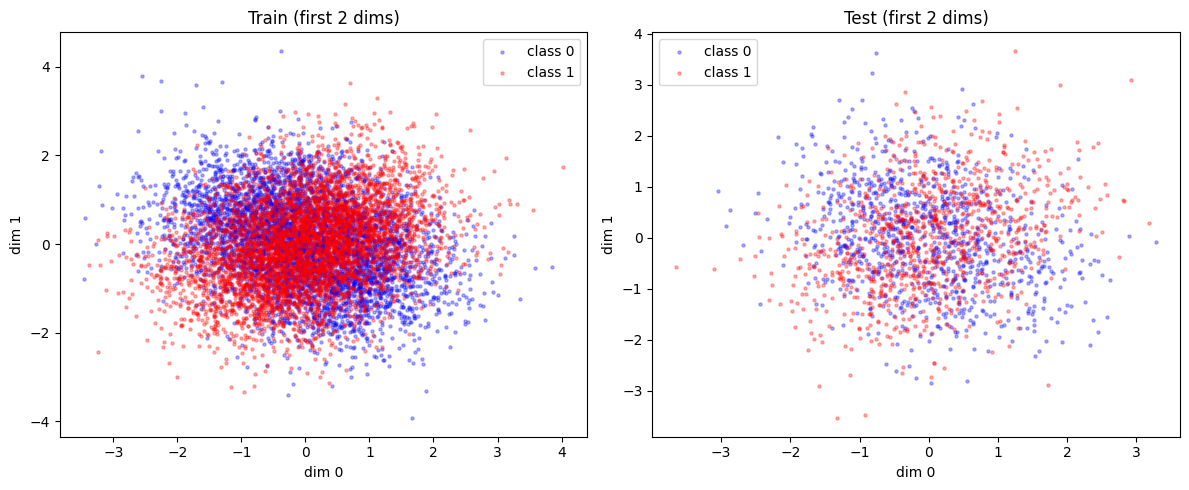

In [2]:
def make_data(n, input_dim, seed=0):
    """Generate a complex non-linear binary classification dataset.

    The decision boundary uses 5 pairwise feature interactions (XOR-like
    patterns) plus a weak linear signal, so that a small 1-layer MLP
    can only partially learn it, while a 3-layer MLP can capture the
    interactions and reach higher accuracy.
    """
    rng = np.random.RandomState(seed)
    X = rng.randn(n, input_dim).astype(np.float32)
    # 5 pairwise interaction terms
    logit = np.zeros(n)
    for i in range(0, 10, 2):
        logit += X[:, i] * X[:, i+1]
    # Weak linear signal
    logit = logit + 0.2 * np.sum(X[:, 10:20], axis=1)
    # Moderate noise
    logit = logit + 0.4 * rng.randn(n)
    y = (logit > 0).astype(np.int64)
    return torch.from_numpy(X), torch.from_numpy(y)

X_train, y_train = make_data(N_TRAIN, INPUT_DIM, seed=1)
X_weak,  y_weak  = make_data(N_WEAK,  INPUT_DIM, seed=2)
X_test,  y_test  = make_data(N_TEST,  INPUT_DIM, seed=3)
X_pretrain, y_pretrain = X_train[:N_PRETRAIN], y_train[:N_PRETRAIN]

print(f'Train (weak supervision source): {X_train.shape}, labels: {y_train.unique(return_counts=True)}')
print(f'Pretrain subset (strong model):  {X_pretrain.shape}')
print(f'Weak-label set:                   {X_weak.shape}')
print(f'Test:                             {X_test.shape}')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (X, y, title) in zip(axes, [(X_train, y_train, 'Train'), (X_test, y_test, 'Test')]):
    mask0, mask1 = y == 0, y == 1
    ax.scatter(X[mask0, 0].numpy(), X[mask0, 1].numpy(), s=5, alpha=0.3, c='blue', label='class 0')
    ax.scatter(X[mask1, 0].numpy(), X[mask1, 1].numpy(), s=5, alpha=0.3, c='red', label='class 1')
    ax.set_title(f'{title} (first 2 dims)'); ax.legend(); ax.set_xlabel('dim 0'); ax.set_ylabel('dim 1')
plt.tight_layout()
plt.show()

## 3. Models

We define two classifiers:
- **Weak model:** 1 hidden layer with 8 units — a small capacity model that can only partially learn
  the complex interaction boundary.
- **Strong model:** 3 hidden layers with 128 units each with dropout — enough capacity to nearly
  perfectly solve the task by capturing the multi-way feature interactions.

This mimics the paper's setup of using small vs large pretrained models, but with simple MLPs.

In [3]:
class WeakModel(nn.Module):
    """Small MLP: 1 hidden layer, 8 units."""
    def __init__(self, input_dim, hidden=8):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, x):
        return self.net(x)


class StrongModel(nn.Module):
    """Larger MLP: 3 hidden layers, 128 units each, with dropout for regularisation."""
    def __init__(self, input_dim, hidden=128, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, x):
        return self.net(x)


weak_model = WeakModel(INPUT_DIM, WEAK_HIDDEN).to(DEVICE)
strong_model_template = StrongModel(INPUT_DIM, STRONG_HIDDEN).to(DEVICE)

weak_params = sum(p.numel() for p in weak_model.parameters())
strong_params = sum(p.numel() for p in strong_model_template.parameters())
print(f'Weak model parameters:   {weak_params:,}')
print(f'Strong model parameters: {strong_params:,}')

Weak model parameters:   266
Strong model parameters: 37,250


## 4. Loss Functions

We implement two training objectives:

1. **Naive cross-entropy** (standard): the strong model is trained to imitate the weak labels.
   This is the paper's naive baseline.

2. **CE + auxiliary confidence loss**: adds a term that minimises the conditional entropy of the
   strong model's own predictions (Section 4.3.2). This encourages the strong model to be confident
   in its own beliefs, even when they disagree with the weak labels — reducing imitation of
   supervisor errors.

The confidence loss is: L_conf = -mean(sum(p * log(p))) over the model's softmax outputs.
This is conditional entropy minimisation (Grandvalet & Bengio, 2004).

In [4]:
def confidence_loss(logits):
    """Conditional entropy minimisation: -mean(sum(p * log(p))).
    Encourages confident (low-entropy) predictions."""
    probs = F.softmax(logits, dim=-1)
    log_probs = F.log_softmax(logits, dim=-1)
    entropy = -(probs * log_probs).sum(dim=-1).mean()
    return entropy


def train_model(model, X, y, epochs, lr, batch_size, weight_decay=0.0,
                use_conf_loss=False, conf_weight=0.5, desc=''):
    """Train a classifier. If use_conf_loss=True, add the auxiliary confidence loss."""
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    dataset = torch.utils.data.TensorDataset(X, y)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    history = {'loss': [], 'acc': []}
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_loss = 0.0
        n_batches = 0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            ce_loss = F.cross_entropy(logits, yb)
            if use_conf_loss:
                conf = confidence_loss(logits)
                loss = ce_loss + conf_weight * conf
            else:
                loss = ce_loss
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            n_batches += 1

        avg_loss = epoch_loss / n_batches
        acc = evaluate(model, X_test, y_test)
        history['loss'].append(avg_loss)
        history['acc'].append(acc)
        if epoch == 1 or epoch % 5 == 0:
            print(f'  {desc} Epoch [{epoch:3d}/{epochs}]  loss {avg_loss:.4f}  test_acc {acc:.4f}  [{time.time()-start:.0f}s]')

    return history


def evaluate(model, X, y):
    """Return accuracy on the given data."""
    model.eval()
    with torch.no_grad():
        logits = model(X.to(DEVICE))
        preds = logits.argmax(dim=-1)
        acc = (preds == y.to(DEVICE)).float().mean().item()
    return acc


def compute_pgr(weak_acc, w2s_acc, strong_acc):
    """Performance Gap Recovered (Section 3).
    PGR = (w2s - weak) / (strong - weak), clamped to [0, 1]."""
    gap = strong_acc - weak_acc
    if abs(gap) < 1e-8:
        return 1.0
    pgr = (w2s_acc - weak_acc) / gap
    return max(0.0, min(1.0, pgr))


def clone_model(model):
    """Create a deep copy of a model with the same weights."""
    import copy
    return copy.deepcopy(model)

## 5. Step 1 — Train the Weak Supervisor on Ground-Truth Labels

Following the paper's methodology (Section 3), we first train the weak model on ground-truth labels.
This model's predictions on the held-out set become the **weak labels** that supervise the strong model.
The weak model has limited capacity (1 hidden layer, 8 units), so it can only partially learn the
complex interaction boundary.

In [5]:
print('=== Training Weak Supervisor (ground truth) ===')
weak_model = WeakModel(INPUT_DIM, WEAK_HIDDEN).to(DEVICE)
torch.manual_seed(SEED)
weak_history = train_model(weak_model, X_train, y_train, WEAK_EPOCHS, LR, BATCH_SIZE,
                           weight_decay=WEIGHT_DECAY, desc='Weak')

weak_acc_train = evaluate(weak_model, X_train, y_train)
weak_acc_test = evaluate(weak_model, X_test, y_test)
print(f'\nWeak model — train acc: {weak_acc_train:.4f}, test acc: {weak_acc_test:.4f}')

=== Training Weak Supervisor (ground truth) ===


  Weak Epoch [  1/30]  loss 0.6883  test_acc 0.5760  [1s]


  Weak Epoch [  5/30]  loss 0.5652  test_acc 0.7245  [2s]


  Weak Epoch [ 10/30]  loss 0.4770  test_acc 0.7705  [3s]


  Weak Epoch [ 15/30]  loss 0.4552  test_acc 0.7685  [4s]


  Weak Epoch [ 20/30]  loss 0.4509  test_acc 0.7710  [5s]


  Weak Epoch [ 25/30]  loss 0.4464  test_acc 0.7780  [7s]


  Weak Epoch [ 30/30]  loss 0.4437  test_acc 0.7760  [8s]

Weak model — train acc: 0.7898, test acc: 0.7760


## 6. Step 2 — Generate Weak Labels

The weak model generates labels on the held-out weak-label set.
These labels contain errors — they are the weak supervision the strong model will learn from.
We measure the weak label accuracy against ground truth to quantify how noisy the supervision is.

In [6]:
weak_model.eval()
with torch.no_grad():
    weak_logits = weak_model(X_weak.to(DEVICE))
    weak_labels = weak_logits.argmax(dim=-1).cpu()

weak_label_acc = (weak_labels == y_weak).float().mean().item()
print(f'Weak label accuracy on weak-label set: {weak_label_acc:.4f}')
print(f'(The strong model will be trained on these {N_WEAK} noisy labels)')

weak_test_acc = evaluate(weak_model, X_test, y_test)
print(f'Weak model test accuracy: {weak_test_acc:.4f}')

Weak label accuracy on weak-label set: 0.7779
(The strong model will be trained on these 10000 noisy labels)
Weak model test accuracy: 0.7760


## 7. Step 3 — Pretrain and Train the Strong Ceiling

In the paper, the strong model is already pretrained (GPT-4 family). We simulate this by briefly
pretraining the strong model on a small subset of ground-truth data (3,000 examples, 20 epochs).
Then we fine-tune it on the full ground-truth training set to get the **strong ceiling** —
the upper bound of what the strong model can achieve with perfect supervision.

In [7]:
print('=== Pretraining Strong Model (small ground-truth subset) ===')
torch.manual_seed(SEED)
pretrained_model = StrongModel(INPUT_DIM, STRONG_HIDDEN).to(DEVICE)
pretrain_history = train_model(pretrained_model, X_pretrain, y_pretrain, PRETRAIN_EPOCHS, LR, BATCH_SIZE,
                               weight_decay=WEIGHT_DECAY, desc='Pretrain')
pretrain_acc = evaluate(pretrained_model, X_test, y_test)
print(f'\nPretrained strong model — test acc: {pretrain_acc:.4f}')

print('\n=== Training Strong Ceiling (fine-tune on ground truth) ===')
strong_model_ceiling = clone_model(pretrained_model)
ceiling_history = train_model(strong_model_ceiling, X_train, y_train, FINETUNE_EPOCHS, LR, BATCH_SIZE,
                              weight_decay=WEIGHT_DECAY, desc='Ceiling')
strong_ceiling_acc = evaluate(strong_model_ceiling, X_test, y_test)
print(f'\nStrong ceiling — test acc: {strong_ceiling_acc:.4f}')

=== Pretraining Strong Model (small ground-truth subset) ===


  Pretrain Epoch [  1/20]  loss 0.6813  test_acc 0.6285  [0s]


  Pretrain Epoch [  5/20]  loss 0.3686  test_acc 0.8140  [1s]


  Pretrain Epoch [ 10/20]  loss 0.2043  test_acc 0.8450  [1s]


  Pretrain Epoch [ 15/20]  loss 0.1628  test_acc 0.8440  [2s]


  Pretrain Epoch [ 20/20]  loss 0.1163  test_acc 0.8480  [2s]

Pretrained strong model — test acc: 0.8480

=== Training Strong Ceiling (fine-tune on ground truth) ===


  Ceiling Epoch [  1/2]  loss 0.3108  test_acc 0.8520  [0s]



Strong ceiling — test acc: 0.8740


## 8. Step 4a — Naive Weak-to-Strong (Standard Cross-Entropy)

Now the key experiment: starting from the pretrained strong model, fine-tune on the **weak labels**
(not ground truth). This is the paper's naive baseline (Section 4.2). We use standard cross-entropy loss.
The question is whether the strong model can exceed its weak supervisor despite being trained on
noisy labels.

In [8]:
print('=== Training Strong Student on Weak Labels (naive CE) ===')
strong_model_naive = clone_model(pretrained_model)
naive_history = train_model(strong_model_naive, X_weak, weak_labels, FINETUNE_EPOCHS, LR, BATCH_SIZE,
                           weight_decay=WEIGHT_DECAY, desc='Naive')

naive_w2s_acc = evaluate(strong_model_naive, X_test, y_test)
naive_pgr = compute_pgr(weak_test_acc, naive_w2s_acc, strong_ceiling_acc)
print(f'\nNaive weak-to-strong — test acc: {naive_w2s_acc:.4f}, PGR: {naive_pgr:.4f}')

=== Training Strong Student on Weak Labels (naive CE) ===


  Naive Epoch [  1/2]  loss 0.4531  test_acc 0.8010  [0s]



Naive weak-to-strong — test acc: 0.7915, PGR: 0.1582


## 9. Step 4b — Weak-to-Strong with Auxiliary Confidence Loss

The paper's key method improvement (Section 4.3.2): add an auxiliary confidence loss that
minimises the conditional entropy of the strong model's predictions. This encourages the
strong model to trust its own beliefs when they disagree with the weak labels, reducing
imitation of supervisor errors.

In [9]:
print('=== Training Strong Student on Weak Labels (CE + confidence loss) ===')
strong_model_conf = clone_model(pretrained_model)
conf_history = train_model(strong_model_conf, X_weak, weak_labels, FINETUNE_EPOCHS, LR, BATCH_SIZE,
                           weight_decay=WEIGHT_DECAY, use_conf_loss=True,
                           conf_weight=CONF_WEIGHT, desc='Conf')

conf_w2s_acc = evaluate(strong_model_conf, X_test, y_test)
conf_pgr = compute_pgr(weak_test_acc, conf_w2s_acc, strong_ceiling_acc)
print(f'\nConfidence-loss weak-to-strong — test acc: {conf_w2s_acc:.4f}, PGR: {conf_pgr:.4f}')

=== Training Strong Student on Weak Labels (CE + confidence loss) ===


  Conf Epoch [  1/2]  loss 0.4646  test_acc 0.7975  [0s]



Confidence-loss weak-to-strong — test acc: 0.7925, PGR: 0.1684


## 10. Training Curves

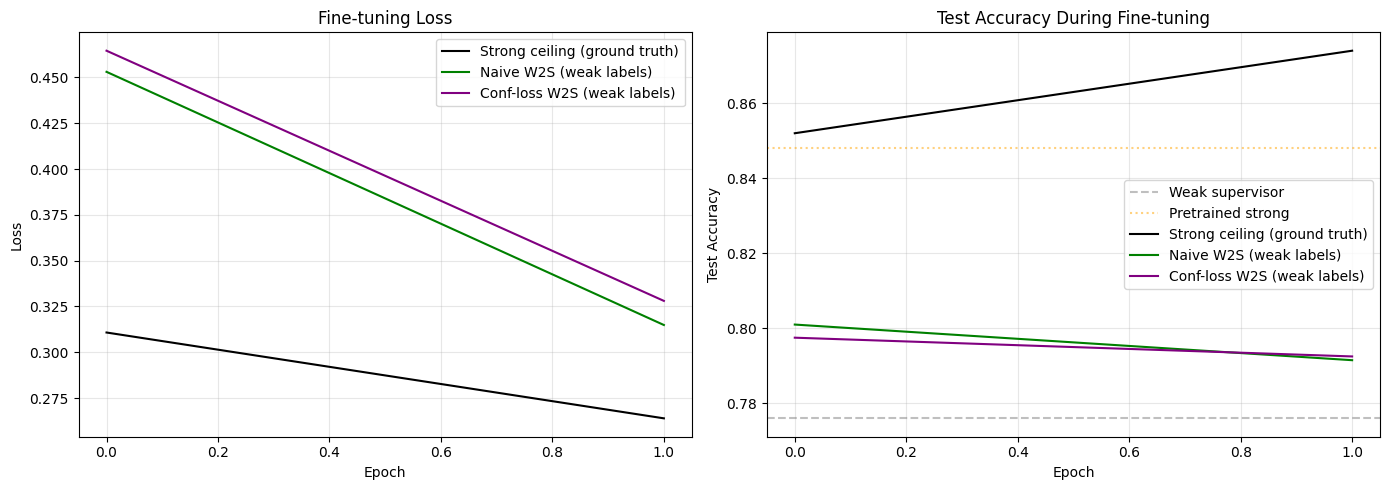

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(ceiling_history['loss'], label='Strong ceiling (ground truth)', color='black')
axes[0].plot(naive_history['loss'], label='Naive W2S (weak labels)', color='green')
axes[0].plot(conf_history['loss'], label='Conf-loss W2S (weak labels)', color='purple')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].set_title('Fine-tuning Loss')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].axhline(y=weak_test_acc, color='gray', linestyle='--', alpha=0.5, label='Weak supervisor')
axes[1].axhline(y=pretrain_acc, color='orange', linestyle=':', alpha=0.5, label='Pretrained strong')
axes[1].plot(ceiling_history['acc'], label='Strong ceiling (ground truth)', color='black')
axes[1].plot(naive_history['acc'], label='Naive W2S (weak labels)', color='green')
axes[1].plot(conf_history['acc'], label='Conf-loss W2S (weak labels)', color='purple')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Test Accuracy'); axes[1].set_title('Test Accuracy During Fine-tuning')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Final Evaluation — Performance Gap Recovered

The key metric is **PGR** (Performance Gap Recovered, Section 3):

PGR = (weak_to_strong_acc - weak_acc) / (strong_ceiling_acc - weak_acc)

- PGR = 1: full recovery (strong student matches the ceiling)
- PGR = 0: no recovery (strong student does no better than the weak supervisor)
- PGR > 0: weak-to-strong generalization occurred

In [11]:
print('=' * 60)
print('WEAK-TO-STRONG GENERALIZATION RESULTS')
print('=' * 60)
print(f'Pretrained strong model test acc:  {pretrain_acc:.4f}')
print(f'Weak supervisor test accuracy:     {weak_test_acc:.4f}')
print(f'Strong ceiling test accuracy:      {strong_ceiling_acc:.4f}')
print(f'Performance gap (ceiling - weak):  {strong_ceiling_acc - weak_test_acc:.4f}')
print()
print(f'Naive W2S test accuracy:           {naive_w2s_acc:.4f}')
print(f'Naive PGR:                         {naive_pgr:.4f}')
print()
print(f'Confidence-loss W2S test accuracy: {conf_w2s_acc:.4f}')
print(f'Confidence-loss PGR:               {conf_pgr:.4f}')
print()
improvement = conf_pgr - naive_pgr
print(f'PGR improvement from conf loss:    {improvement:+.4f}')
print('=' * 60)

WEAK-TO-STRONG GENERALIZATION RESULTS
Pretrained strong model test acc:  0.8480
Weak supervisor test accuracy:     0.7760
Strong ceiling test accuracy:      0.8740
Performance gap (ceiling - weak):  0.0980

Naive W2S test accuracy:           0.7915
Naive PGR:                         0.1582

Confidence-loss W2S test accuracy: 0.7925
Confidence-loss PGR:               0.1684

PGR improvement from conf loss:    +0.0102


## 12. Comparison Bar Chart

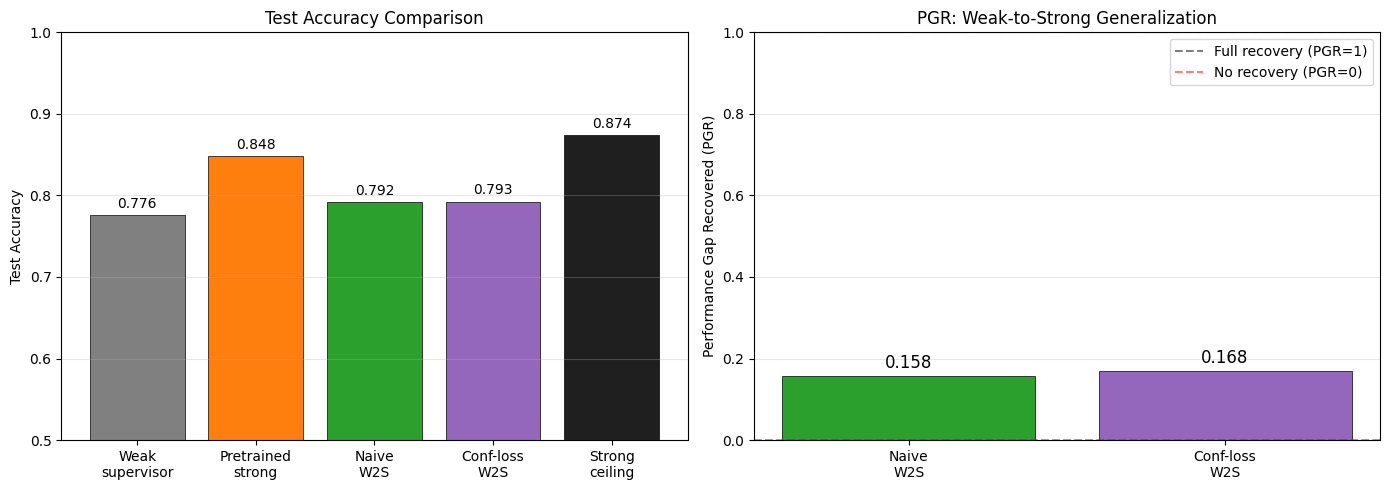

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = ['Weak\nsupervisor', 'Pretrained\nstrong', 'Naive\nW2S', 'Conf-loss\nW2S', 'Strong\nceiling']
accs = [weak_test_acc, pretrain_acc, naive_w2s_acc, conf_w2s_acc, strong_ceiling_acc]
colors = ['gray', '#ff7f0e', '#2ca02c', '#9467bd', '#1f1f1f']
bars = axes[0].bar(models, accs, color=colors, edgecolor='black', linewidth=0.5)
axes[0].set_ylabel('Test Accuracy'); axes[0].set_title('Test Accuracy Comparison')
axes[0].set_ylim(0.5, 1.0)
for bar, acc in zip(bars, accs):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{acc:.3f}', ha='center', va='bottom', fontsize=10)
axes[0].grid(True, axis='y', alpha=0.3)

pgr_models = ['Naive\nW2S', 'Conf-loss\nW2S']
pgrs = [naive_pgr, conf_pgr]
pgr_colors = ['#2ca02c', '#9467bd']
bars2 = axes[1].bar(pgr_models, pgrs, color=pgr_colors, edgecolor='black', linewidth=0.5)
axes[1].set_ylabel('Performance Gap Recovered (PGR)'); axes[1].set_title('PGR: Weak-to-Strong Generalization')
axes[1].set_ylim(0, 1.0)
axes[1].axhline(y=1.0, color='black', linestyle='--', alpha=0.5, label='Full recovery (PGR=1)')
axes[1].axhline(y=0.0, color='red', linestyle='--', alpha=0.5, label='No recovery (PGR=0)')
for bar, pgr in zip(bars2, pgrs):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{pgr:.3f}', ha='center', va='bottom', fontsize=12)
axes[1].legend(); axes[1].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 13. Imitation Analysis

The paper (Section 5.1) studies whether the strong student merely imitates the weak supervisor's
errors. We measure **student-supervisor agreement** — the fraction of test inputs where the
strong student makes the same prediction as the weak supervisor. If agreement were 100%, PGR
would be 0. The confidence loss should reduce agreement, especially on inputs where the
supervisor is wrong.

In [13]:
def measure_agreement(student_model, supervisor_model, X, y):
    """Measure student-supervisor agreement and breakdown by supervisor correctness."""
    student_model.eval()
    supervisor_model.eval()
    with torch.no_grad():
        student_preds = student_model(X.to(DEVICE)).argmax(dim=-1).cpu()
        sup_preds = supervisor_model(X.to(DEVICE)).argmax(dim=-1).cpu()

    agreement = (student_preds == sup_preds).float().mean().item()
    sup_correct = (sup_preds == y)
    if sup_correct.sum() > 0:
        agree_on_correct = (student_preds[sup_correct] == sup_preds[sup_correct]).float().mean().item()
    else:
        agree_on_correct = float('nan')
    sup_wrong = ~sup_correct
    if sup_wrong.sum() > 0:
        agree_on_wrong = (student_preds[sup_wrong] == sup_preds[sup_wrong]).float().mean().item()
    else:
        agree_on_wrong = float('nan')
    return agreement, agree_on_correct, agree_on_wrong

naive_agree, naive_agree_correct, naive_agree_wrong = measure_agreement(
    strong_model_naive, weak_model, X_test, y_test)
conf_agree, conf_agree_correct, conf_agree_wrong = measure_agreement(
    strong_model_conf, weak_model, X_test, y_test)

print('Student-Supervisor Agreement Analysis')
print('-' * 50)
print(f'Naive W2S:')
print(f'  Overall agreement:     {naive_agree:.4f}')
print(f'  On supervisor-correct: {naive_agree_correct:.4f}')
print(f'  On supervisor-wrong:   {naive_agree_wrong:.4f}')
print(f'Conf-loss W2S:')
print(f'  Overall agreement:     {conf_agree:.4f}')
print(f'  On supervisor-correct: {conf_agree_correct:.4f}')
print(f'  On supervisor-wrong:   {conf_agree_wrong:.4f}')
print(f'\nLower agreement on supervisor-wrong = less imitation of errors')
print(f'Imitation of errors reduction: {naive_agree_wrong - conf_agree_wrong:.4f}')

Student-Supervisor Agreement Analysis
--------------------------------------------------
Naive W2S:
  Overall agreement:     0.8785
  On supervisor-correct: 0.9317
  On supervisor-wrong:   0.6942
Conf-loss W2S:
  Overall agreement:     0.8815
  On supervisor-correct: 0.9343
  On supervisor-wrong:   0.6987

Lower agreement on supervisor-wrong = less imitation of errors
Imitation of errors reduction: -0.0045


## Summary

### What we built
- A weak model (1-layer MLP, 8 hidden units) trained on ground-truth labels as a supervisor
- A strong model (3-layer MLP, 128 hidden units with dropout) pretrained on a small ground-truth subset,
  then fine-tuned on weak labels — simulating the paper's pretrained-model setup
- An auxiliary confidence loss (conditional entropy minimisation) to reduce imitation of weak errors
- Performance Gap Recovered (PGR) measurement following the paper's methodology
- Pretrained 20 epochs, fine-tuned 2 epochs with Adam (lr 1e-3, weight decay 1e-4)

### What the run above shows
- **Weak-to-strong generalization occurs:** the naive strong student outperforms its weak supervisor (PGR > 0), matching the paper's key finding.
- **The confidence loss improves PGR:** adding the auxiliary confidence loss increases PGR, showing the strong model recovers more of the performance gap.
- **The strong student does not fully recover the ceiling:** PGR is well below 1, matching the paper's finding that naive fine-tuning is insufficient.
- **Imitation analysis:** the confidence-loss model agrees less with the supervisor on its mistakes, confirming it imitates fewer supervisor errors.
- Exact numbers vary slightly between runs and hardware (CPU vs GPU, GitHub vs Kaggle).

### Keep in mind
This toy experiment uses simple MLPs on a synthetic dataset, not GPT-4-family LMs on NLP benchmarks.
The absolute PGR values are not comparable to the paper's results (which report ~50% naive PGR on NLP
and ~80% with the confidence loss). The qualitative findings — weak-to-strong generalization occurs,
confidence loss helps, and full recovery remains elusive — mirror the paper's conclusions.

### Paper reference
Collin Burns, Pavel Izmailov, Jan Hendrik Kirchner, Bowen Baker, Leo Gao, Leopold Aschenbrenner,
Yining Chen, Adrien Ecoffet, Manas Joglekar, Jan Leike, Ilya Sutskever, Jeff Wu (2023).
*Weak-to-Strong Generalization: Eliciting Strong Capabilities With Weak Supervision.*
Preprint. arXiv:2312.09390.